# 基于采样的量子对角化（SQD）：12 比特示例

这个示例使用 MOSSQuantum 构造一个保激发数的参数化线路，先优化线路参数，再用有限次计算基采样确定子空间，最后对投影哈密顿量进行经典对角化。优化前后的采样次数与随机数起点相同，便于比较。

本 Notebook 与命令行入口 `run.jl` 共用 `sqd.jl` 中的实现；请按顺序运行单元格。从仓库根目录或本 Notebook 所在目录启动 Jupyter，并选择已安装 IJulia 的 Julia 内核。首次运行前需按仓库 README 安装 MOSSQuantum 项目和 Algorithm Zoo 的绘图依赖。

In [ ]:
using Pkg

# 从工作目录向上查找 MOSSQuantum 仓库；可从项目根目录或本 Notebook 目录启动。
function find_mossquantum_root(start=pwd())
    dir = abspath(start)
    while true
        if isfile(joinpath(dir, "Project.toml")) && isfile(joinpath(dir, "src", "MOSSQuantum.jl"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && error("未找到 MOSSQuantum 仓库；请从仓库根目录或 algorithm_zoo/sqd 启动 Jupyter")
        dir = parent
    end
end
root = find_mossquantum_root()
Pkg.activate(root)
# 图表依赖单独安装在 Algorithm Zoo 的环境中，不更改 MOSSQuantum 核心依赖。
zoo_environment = joinpath(root, "algorithm_zoo")
zoo_environment in LOAD_PATH || push!(LOAD_PATH, zoo_environment)
using MOSSQuantum, Random, LinearAlgebra, Plots
if !isdefined(Main, :SQDExample)
    include(joinpath(root, "algorithm_zoo", "sqd", "sqd.jl"))
end
using .SQDExample
println("MOSSQuantum 项目目录：", root)

## 1. 模型与问题

考虑 12 个位点组成的环，限制总激发数为 6。记 $n_i=|1\rangle\langle 1|_i$，模型为

$$H=\sum_i\epsilon_i n_i+0.25\sum_i n_i n_{i+1}+\sum_i t_i(\sigma_i^+\sigma_{i+1}^-+\sigma_i^-\sigma_{i+1}^+),$$

其中 $\epsilon_i=-0.55+0.10(i-1)+0.04\sin i$，$t_i=0.6+0.15\cos i$，并令第 13 个位点等同于第 1 个位点。它保持激发数，因此六激发扇区包含 $\binom{12}{6}=924$ 个计算基态。我们的目标是估计这个扇区的最低能量。

In [ ]:
nqubits, particles = 12, 6
shots, iterations, seed = 32768, 350, 42
hamiltonian = toy_hamiltonian()
sector = particle_sector(nqubits, particles)
println("比特数：", nqubits, "；激发数：", particles, "；扇区维度：", length(sector))
println("采样次数：", shots, "；优化步数：", iterations)

## 2. 参数化线路与变分目标

线路先在每对相邻比特中制备一个激发，再使用八层局域部分交换门；44 个交换角是可优化参数。目标是最小化线路状态的能量期望：

$$E(\theta)=\langle\psi(\theta)|H|\psi(\theta)\rangle.$$

这里使用理想 MOSSQuantum 模拟态的振幅与完整六激发扇区中的稀疏哈密顿量计算期望；**优化不使用参考基态本征值或本征矢**。这是一种便于演示的模拟器目标，量子硬件上的期望需要通过测量哈密顿量各项估计，本示例没有实现这一过程。

In [ ]:
initial_angles = initial_parameters()
sector_hamiltonian = projected_hamiltonian(sector, hamiltonian)
initial_energy = variational_energy(initial_angles, sector, sector_hamiltonian)
println("参数个数：", length(initial_angles))
println("初始变分能量：", initial_energy)

## 3. 优化线路参数

使用中心有限差分估计每个角度的梯度，用 Adam 更新，并保留能量最低的已访问参数。默认 350 步需要 31,151 次线路求值；可以在第 1 节调整迭代次数以加快试运行，但精度可能下降。每 50 步额外记录截至当时最低变分能量对应的参数，以便后续实际采样并计算 SQD 能量。

In [ ]:
optimization = optimize_parameters(hamiltonian; iterations=iterations, initial=initial_angles, checkpoint_interval=50)
println("最优变分能量：", optimization.final_energy)
println("线路求值次数：", optimization.evaluations)
println("每 50 步的能量：")
for i in 0:iterations
    if i % 50 == 0 || i == iterations
        println("  ", i, " => ", optimization.energy_history[i + 1])
    end
end

## 4. 用 MOSSQuantum 采样并筛选计算基

分别执行初始线路和优化后的线路，使用相同采样数及相同的随机数初始状态。每个采样行是一个计算基比特串；筛选六激发构型并去重后得到两个子空间。MOSSQuantum 的第 $q$ 列对应比特 $q$，比特 1 是基态整数索引的最低有效位。

In [ ]:
initial_state = preparation_circuit(initial_angles) * StateVector(nqubits)
optimized_state = preparation_circuit(optimization.parameters) * StateVector(nqubits)
initial_samples = sample(MersenneTwister(seed), initial_state, shots)
optimized_samples = sample(MersenneTwister(seed), optimized_state, shots)
initial_basis = sampled_basis(initial_samples; particles=particles)
optimized_basis = sampled_basis(optimized_samples; particles=particles)
println("初始 / 优化后子空间维度：", length(initial_basis), " / ", length(optimized_basis))
println("示例比特串（从左到右为 q1 到 q12）：")
println([join((index >> (q - 1)) & 1 for q in 1:nqubits) for index in optimized_basis[1:min(8, end)]])

## 5. 投影哈密顿量并对角化

对去重后的基 $\{|b_i\rangle\}$ 构造投影矩阵 $H_S[i,j]=\langle b_i|H|b_j\rangle$，并求其最低本征值。**采样中出现过的构型决定基，采样频率不是本征矢系数**；这些系数由经典对角化确定。代码直接构造所需的稀疏矩阵，不构造完整的 $4096\times4096$ 稠密矩阵。

In [ ]:
initial_sqd = solve_subspace(initial_basis, hamiltonian)
optimized_sqd = solve_subspace(optimized_basis, hamiltonian)
println("初始 SQD 能量：", initial_sqd.energy, "；残差：", initial_sqd.residual)
println("优化后 SQD 能量：", optimized_sqd.energy, "；残差：", optimized_sqd.residual)

## 6. 与完整扇区参考比较

为了评估这个 12 比特示例，我们单独求解完整 924 维六激发扇区。它仅用于最终比较，不用于优化。采样子空间的最低能量是扇区基态能量的变分上界（允许数值误差）；有限采样可能遗漏重要构型，因此这种接近程度只针对当前配置和随机种子。

In [ ]:
reference = solve_subspace(sector, hamiltonian)
error_before = initial_sqd.energy - reference.energy
error_after = optimized_sqd.energy - reference.energy
println("完整扇区参考能量：", reference.energy, "；残差：", reference.residual)
println("优化前误差：", error_before)
println("优化后误差：", error_after)
println("优化后相对误差：", abs(error_after / reference.energy) * 100, "%")

## 7. 图表：优化过程中能量与误差

下面的连续线是每一步的**理想模拟态变分能量**，不是 SQD 采样估计。圆点则在每 50 步实际重新制备截至该步变分能量最低的线路，使用相同的 `shots` 和随机数种子采样、构造子空间并对角化，得到对应的 **SQD 能量**。第 0 步和最后一步复用前面已经计算的结果。

两者的绝对误差都与完整六激发扇区的参考能量比较。为便于看清数量级，右图采用对数纵轴；数值舍入导致的非正误差按 $10^{-12}$ 显示。这只是一个种子和一组超参数的实验，并非统计置信区间。中间检查点需要额外采样和对角化。


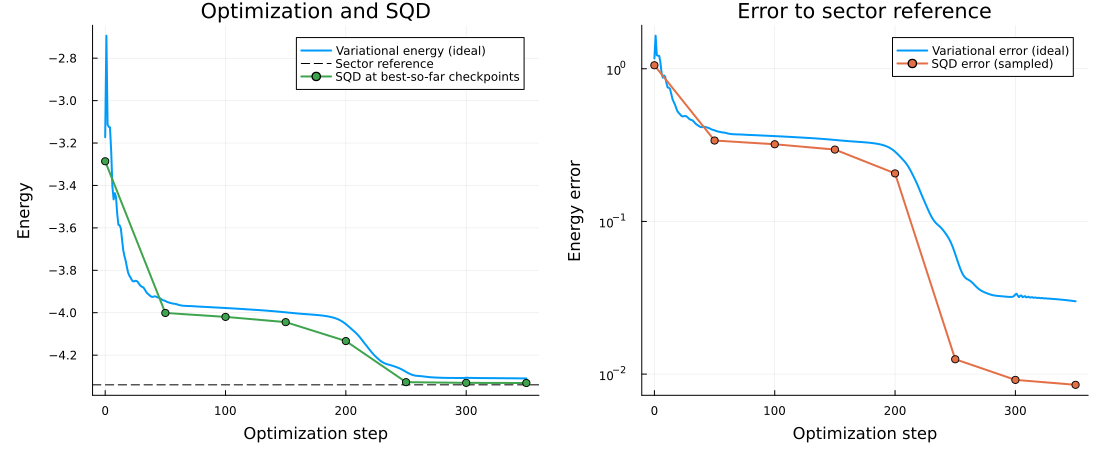

In [ ]:
# 变分能量记录的是每次实际迭代；SQD 检查点使用截至该步的最佳参数。
checkpoint_sqd = [
    if checkpoint.iteration == 0
        initial_sqd
    elseif checkpoint.iteration == iterations
        optimized_sqd
    else
        checkpoint_state = preparation_circuit(checkpoint.parameters) * StateVector(nqubits)
        checkpoint_samples = sample(MersenneTwister(seed), checkpoint_state, shots)
        checkpoint_basis = sampled_basis(checkpoint_samples; particles=particles)
        solve_subspace(checkpoint_basis, hamiltonian)
    end
    for checkpoint in optimization.checkpoints
]
checkpoint_steps = [checkpoint.iteration for checkpoint in optimization.checkpoints]
checkpoint_energies = [result.energy for result in checkpoint_sqd]
energy_plot = plot(0:iterations, optimization.energy_history;
    xlabel="Optimization step", ylabel="Energy", label="Variational energy (ideal)",
    title="Optimization and SQD", linewidth=2, legend=:topright,
    left_margin=8Plots.mm, bottom_margin=8Plots.mm)
hline!(energy_plot, [reference.energy]; label="Sector reference", linestyle=:dash, color=:black)
plot!(energy_plot, checkpoint_steps, checkpoint_energies;
    label="SQD at best-so-far checkpoints", marker=:circle, linewidth=2)
error_floor = 1e-12
error_plot = plot(0:iterations, max.(optimization.energy_history .- reference.energy, error_floor);
    xlabel="Optimization step", ylabel="Energy error", yscale=:log10,
    label="Variational error (ideal)", title="Error to sector reference", linewidth=2,
    left_margin=8Plots.mm, bottom_margin=8Plots.mm)
plot!(error_plot, checkpoint_steps, max.(checkpoint_energies .- reference.energy, error_floor);
    label="SQD error (sampled)", marker=:circle, linewidth=2)
plot(energy_plot, error_plot; layout=(1, 2), size=(1100, 460))


## 8. 图表：采样次数与 SQD 精度

以下曲线分别使用前面得到的初始和优化后采样序列的**累积前缀**，对每个采样次数重新建立 SQD 子空间并计算能量误差。随着前缀增大，子空间嵌套，因此理论上的投影最低能量不会上升；最末点复用前面的结果。这里只展示一个随机种子，不是跨种子平均或置信区间。对于与参考值的差因数值舍入为非正的情况，图中同样以 $10^{-12}$ 作对数坐标下限。


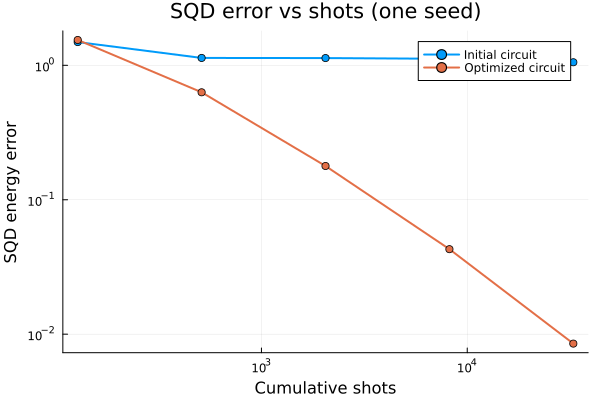

In [ ]:
shot_grid = sort!(unique!([filter(n -> n < shots, [128, 512, 2048, 8192]); shots]))
initial_shot_results = [
    n == shots ? initial_sqd : solve_subspace(sampled_basis(view(initial_samples, 1:n, :); particles=particles), hamiltonian)
    for n in shot_grid
]
optimized_shot_results = [
    n == shots ? optimized_sqd : solve_subspace(sampled_basis(view(optimized_samples, 1:n, :); particles=particles), hamiltonian)
    for n in shot_grid
]
shot_error_plot = plot(shot_grid,
    max.([r.energy - reference.energy for r in initial_shot_results], error_floor);
    xscale=:log10, yscale=:log10, marker=:circle, linewidth=2,
    label="Initial circuit", xlabel="Cumulative shots", ylabel="SQD energy error",
    title="SQD error vs shots (one seed)")
plot!(shot_error_plot, shot_grid,
    max.([r.energy - reference.energy for r in optimized_shot_results], error_floor);
    marker=:circle, linewidth=2, label="Optimized circuit")


默认 Julia 1.13.1 运行中，优化后的 SQD 能量约为 −4.33136，完整扇区参考值约为 −4.33987，绝对差约为 0.00851。实际采样结果取决于随机种子、采样次数与优化设置。

这个例子不包含量子化学积分、噪声下构型恢复、自洽迭代或硬件运行。全状态模拟与完整扇区枚举仍有指数扩展成本；本例用于说明流程与验证结果，而非展示量子优势。

参考资料：[SQD 原始论文](https://arxiv.org/abs/2405.05068)；[IBM SQD 介绍](https://qiskit.qotlabs.org/learning/courses/quantum-diagonalization-algorithms/sqd-overview)。